#### 1) Problem Statement  
- This project understands how the students' performance (test scores) in high school is affected by other variables such as Gender, Ethnicity, Parental level of education, Lunch, and Test preparation course.  

#### 2) Data Collection  
- Dataset Source: https://www.kaggle.com/datasets/spscientist/students-performance-in-exams?datasetid=74977
- The data consists of 8 columns and 1000 rows.

**2.1 Import Data and Required Packages**  
- Importing Pandas, Numpy, Matplotlib, Seaborn, and Warnings library 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

Import the CSV Data as Pandas DataFrame

In [2]:
df = pd.read_csv("data/stud.csv")

Show Top 5 Records

In [3]:
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Shape of the dataset

In [4]:
df.shape

(1000, 8)

**2.2 Dataset Information**  
- `gender`: sex of students -> (Male / Female)
- `race_ethnicity`: ethnicity of students -> (Group A, B, C, D, E)
- `parental_level_of_education`: parents' final education -> (bachelor's degree, some college, master's degree, associate's degree, high school)
- `lunch`: having lunch before test -> (standard or free/reduced)
- `test_preparation_course`: complete or not complete before test
- `math_score`
- `reading_score`
- `writing_score`

#### 3) Data Checks to Perform
- Check missing values
- Check duplicate values
- Check data types
- Check the number of unique values of each column
- Check statistics of dataset
- Check various categories present in the different categorical columns

**3.1 Check missing values**

In [5]:
df.isna().sum()

gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

There are no missing values in the dataset.

**3.2 Check duplicates**

In [8]:
df.duplicated().sum()

np.int64(0)

There are no duplicate values in the dataset.

**3.3 Check data types**

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


**3.4 Check the number of unique values of each column**

In [13]:
df.nunique()

gender                          2
race_ethnicity                  5
parental_level_of_education     6
lunch                           2
test_preparation_course         2
math_score                     81
reading_score                  72
writing_score                  77
dtype: int64

**3.5 Check statistics of dataset**

In [14]:
df.describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


**Insight:**  
- From the above description of the numerical data, all means are very close to each other (ranging between 66-69).
- All standard deviations are also very close (between 14.6 and 15.19).
- The minimum score for math is 0, but it is much higher for writing (10) and reading (17).

**3.7 Exploring Data**

In [19]:
print("Categories in 'gender' variable:         ", end="\n")
print(df["gender"].unique(), end="\n\n")

print("Categories in 'race/ethnicity' variable:         ", end="\n")
print(df["race_ethnicity"].unique(), end="\n\n")

print("Categories in 'parental_level_of_education' variable:         ", end="\n")
print(df["parental_level_of_education"].unique(), end="\n\n")

print("Categories in 'lunch' variable:         ", end="\n")
print(df["lunch"].unique(), end="\n\n")

print("Categories in 'test_preparation_course' variable:         ", end="\n")
print(df["test_preparation_course"].unique(), end="\n\n")

Categories in 'gender' variable:         
<StringArray>
['female', 'male']
Length: 2, dtype: str

Categories in 'race/ethnicity' variable:         
<StringArray>
['group B', 'group C', 'group A', 'group D', 'group E']
Length: 5, dtype: str

Categories in 'parental_level_of_education' variable:         
<StringArray>
[ 'bachelor's degree',       'some college',    'master's degree',
 'associate's degree',        'high school',   'some high school']
Length: 6, dtype: str

Categories in 'lunch' variable:         
<StringArray>
['standard', 'free/reduced']
Length: 2, dtype: str

Categories in 'test_preparation_course' variable:         
<StringArray>
['none', 'completed']
Length: 2, dtype: str



In [35]:
# defining numerical & categorical features
numerical_features = [feature for feature in df.columns if df[feature].dtype != "str"]
categorical_features = [feature for feature in df.columns if df[feature].dtype == "str"]

print(f"There are {len(numerical_features)} numerical features: {numerical_features}")
print(f"There are {len(categorical_features)} categorical features: {categorical_features}")

There are 3 numerical features: ['math_score', 'reading_score', 'writing_score']
There are 5 categorical features: ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


**3.8 Adding Columns for "Total Score" and "Average Score"**

In [36]:
df["total_score"] = df["math_score"] + df["reading_score"] + df["writing_score"]
df["average_score"] = df["total_score"]/3

df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [45]:
math_full = df[df["math_score"]==100]["average_score"].count()
reading_full = df[df["reading_score"]==100]["average_score"].count()
writing_full = df[df["writing_score"]==100]["average_score"].count()

print(f"Number of students with full marks in Math: {math_full}")
print(f"Number of students with full marks in Reading: {reading_full}")
print(f"Number of students with full marks in Writing: {writing_full}")

Number of students with full marks in Math: 7
Number of students with full marks in Reading: 17
Number of students with full marks in Writing: 14


In [46]:
math_less_20 = df[df["math_score"]<=20]["average_score"].count()
reading_less_20 = df[df["reading_score"]<=20]["average_score"].count()
writing_less_20 = df[df["writing_score"]<=20]["average_score"].count()

print(f"Number of students with less than 20 marks in Math: {math_less_20}")
print(f"Number of students with less than 20 marks in Reading: {reading_less_20}")
print(f"Number of students with less than 20 marks in Writing: {writing_less_20}")

Number of students with less than 20 marks in Math: 4
Number of students with less than 20 marks in Reading: 1
Number of students with less than 20 marks in Writing: 3


**Insights:**  
- Students have performed worst in Math
- Students have performed best in Reading section

#### 4) Exploring Data (Visualization)

**4.1 Visualize average score distribution to make some conclusion**  
- Histogram
- Kernel Density Function (KDE)

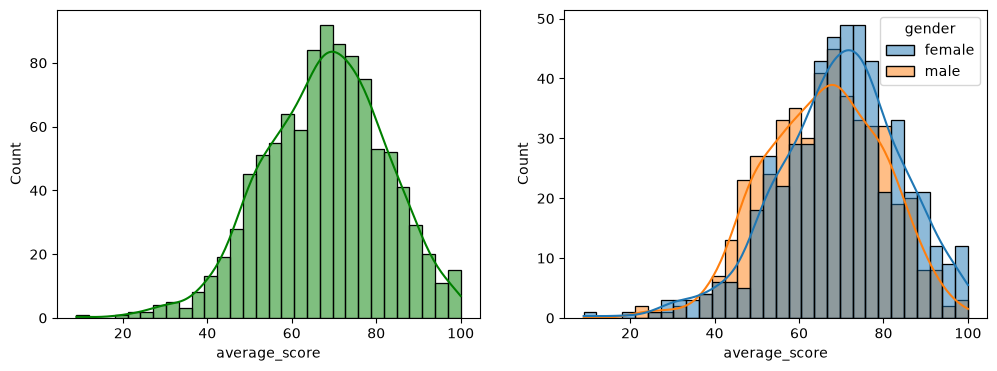

In [48]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

plt.subplot(121)
sns.histplot(data=df, x="average_score", bins=30, kde=True, color="g")
plt.subplot(122)
sns.histplot(data=df, x="average_score", bins=30, kde=True, hue="gender")

plt.show()

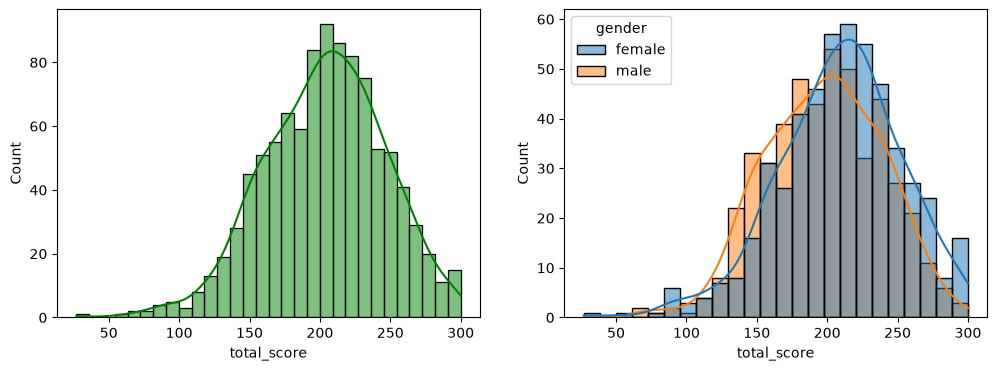

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

plt.subplot(121)
sns.histplot(data=df, x="total_score", bins=30, kde=True, color="g")
plt.subplot(122)
sns.histplot(data=df, x="total_score", kde=True, hue="gender")

plt.show()

**Insight:**  
- Female students tend to perform better than male students.

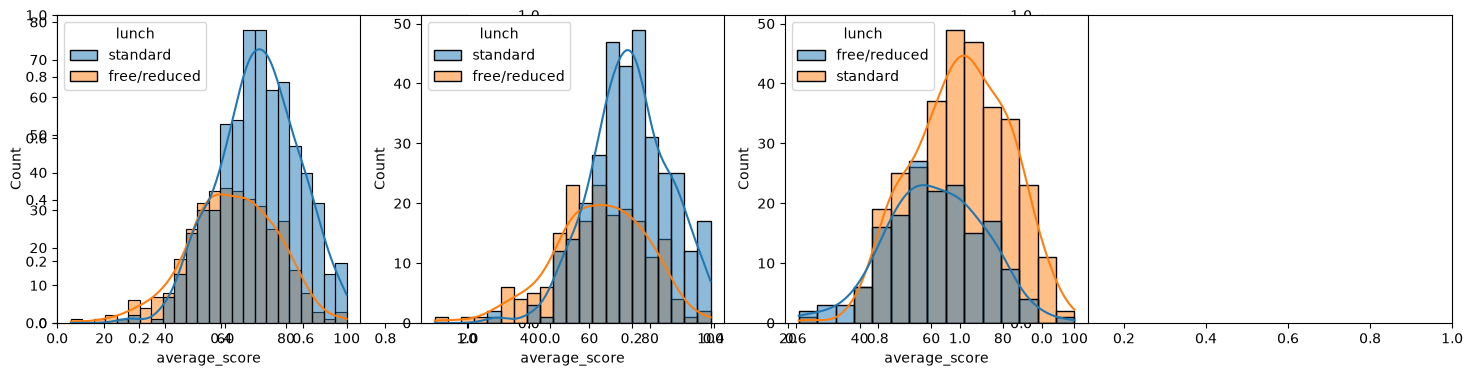

In [57]:
plt.subplots(1, 3, figsize=(18, 4))

plt.subplot(141)
sns.histplot(data=df, x="average_score", kde=True, hue="lunch")
plt.subplot(142)
sns.histplot(data=df[df["gender"]=="female"], x="average_score", kde=True, hue="lunch")
plt.subplot(143)
sns.histplot(data=df[df["gender"]=="male"], x="average_score", kde=True, hue="lunch")

plt.show()

**Insight:**  
- Standard lunch helps both male and female students to perform well in exams.

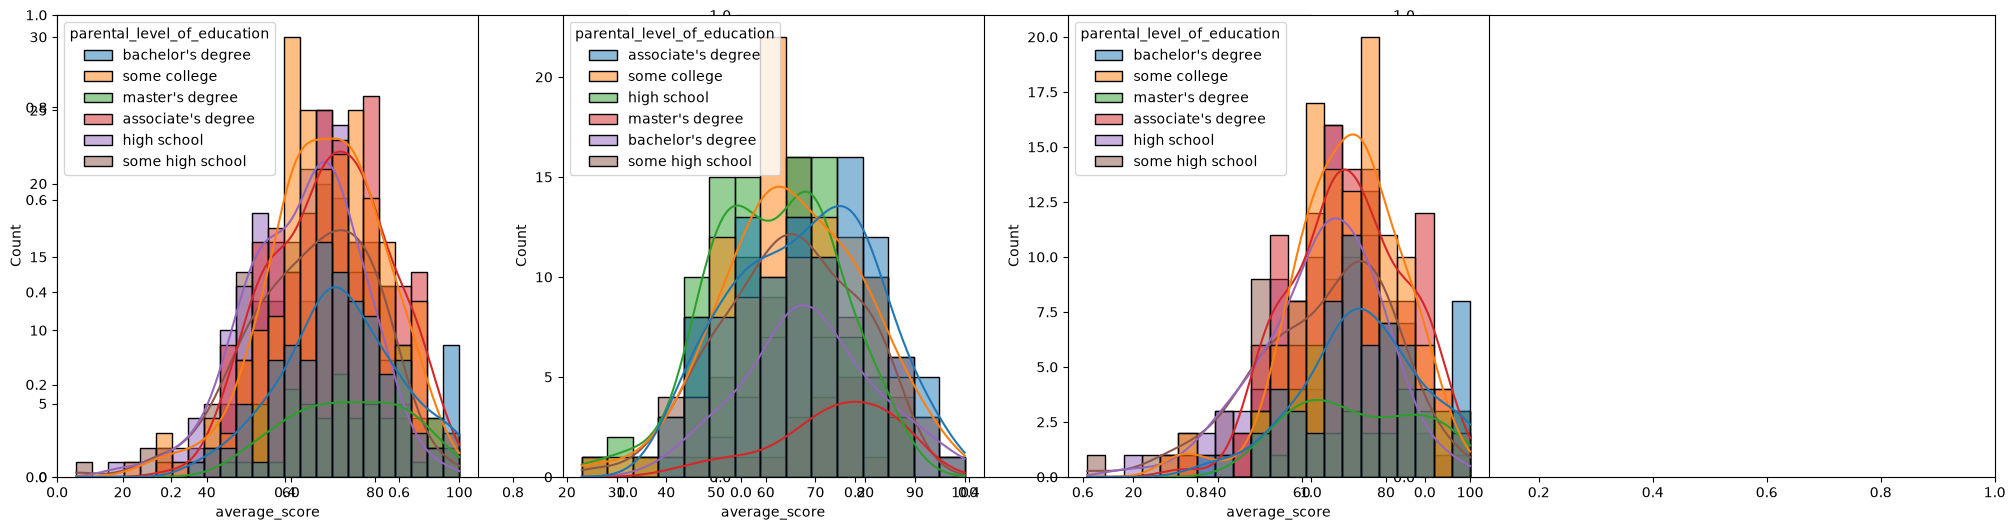

In [58]:
plt.subplots(1,3,figsize=(25,6))

plt.subplot(141)
ax =sns.histplot(data=df, x="average_score", kde=True, hue="parental_level_of_education")
plt.subplot(142)
ax =sns.histplot(data=df[df.gender=="male"], x="average_score", kde=True, hue="parental_level_of_education")
plt.subplot(143)
ax =sns.histplot(data=df[df.gender=="female"], x="average_score", kde=True,hue="parental_level_of_education")

plt.show()

**Insights:**  
- In general parent's education don't help student perform well in exam.
- 2nd plot shows that parent's whose education is of associate's degree or master's degree their male child tend to perform well in exam
- 3rd plot we can see there is no effect of parent's education on female students.

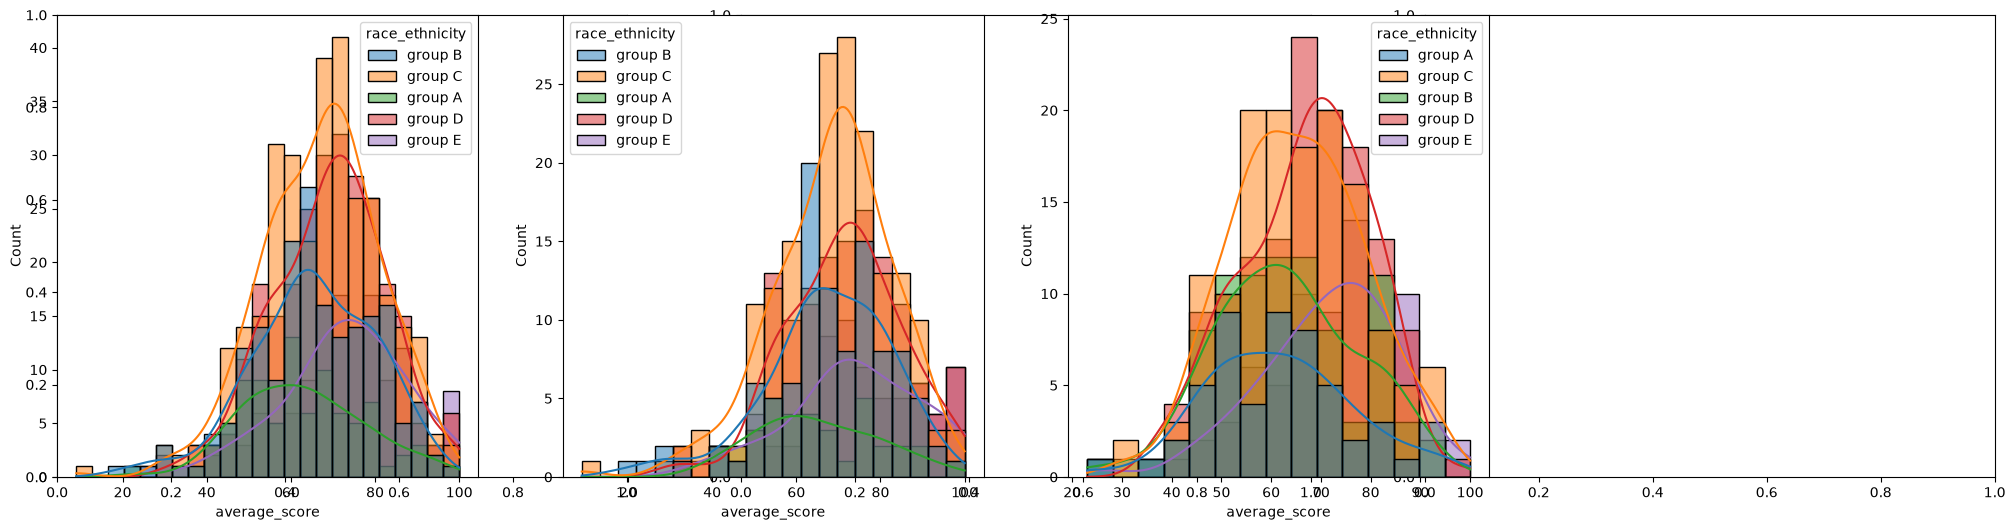

In [60]:
plt.subplots(1,3,figsize=(25,6))

plt.subplot(141)
ax =sns.histplot(data=df, x="average_score", kde=True, hue="race_ethnicity")

plt.subplot(142)
ax =sns.histplot(data=df[df.gender=="female"], x="average_score", kde=True, hue="race_ethnicity")

plt.subplot(143)
ax =sns.histplot(data=df[df.gender=="male"], x="average_score", kde=True, hue="race_ethnicity")

plt.show()

**Insights:**  
- Students of group A and group B tends to perform poorly in exam irrespective of whether they are male or female.

**4.2 Maximum score of students in all three tests**

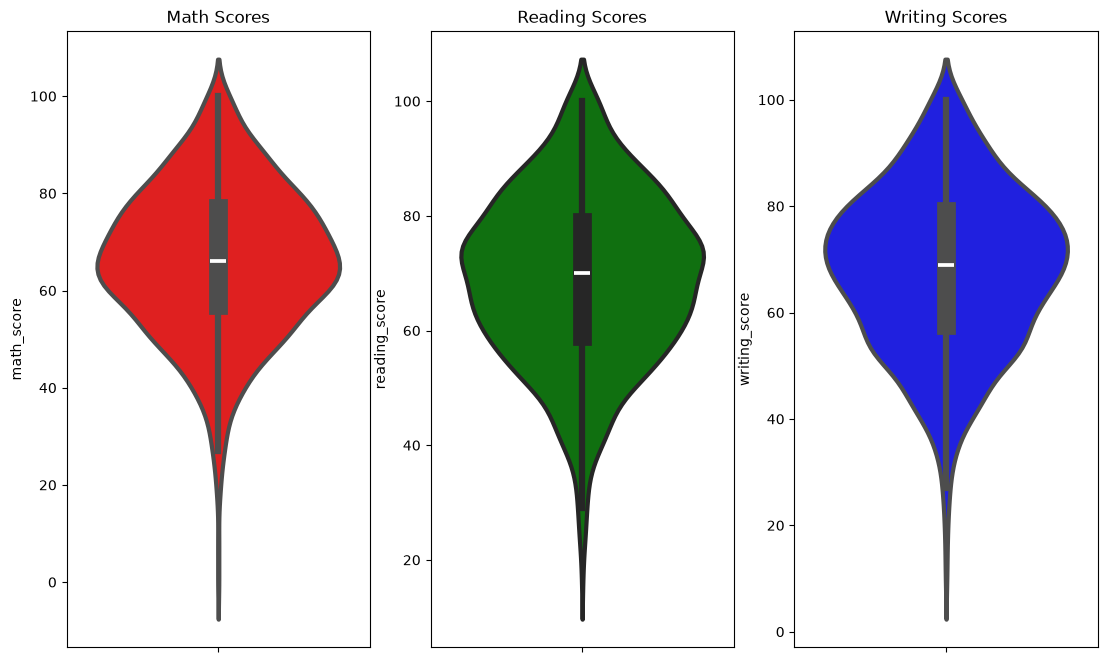

In [62]:
plt.figure(figsize=(18,8))

plt.subplot(1, 4, 1)
plt.title("Math Scores")
sns.violinplot(data=df, y="math_score", color="red", linewidth=3)

plt.subplot(1, 4, 2)
plt.title("Reading Scores")
sns.violinplot(data=df, y="reading_score", color="green", linewidth=3)

plt.subplot(1, 4, 3)
plt.title("Writing Scores")
sns.violinplot(data=df, y="writing_score", color="blue", linewidth=3)

plt.show()

**Insights:**  
- From the above three plots its clearly visible that most of the students score in between 60-80 in Maths whereas in reading and writing most of them score from 50-80.

**4.3 Multivariate Analysis using Pie plot**

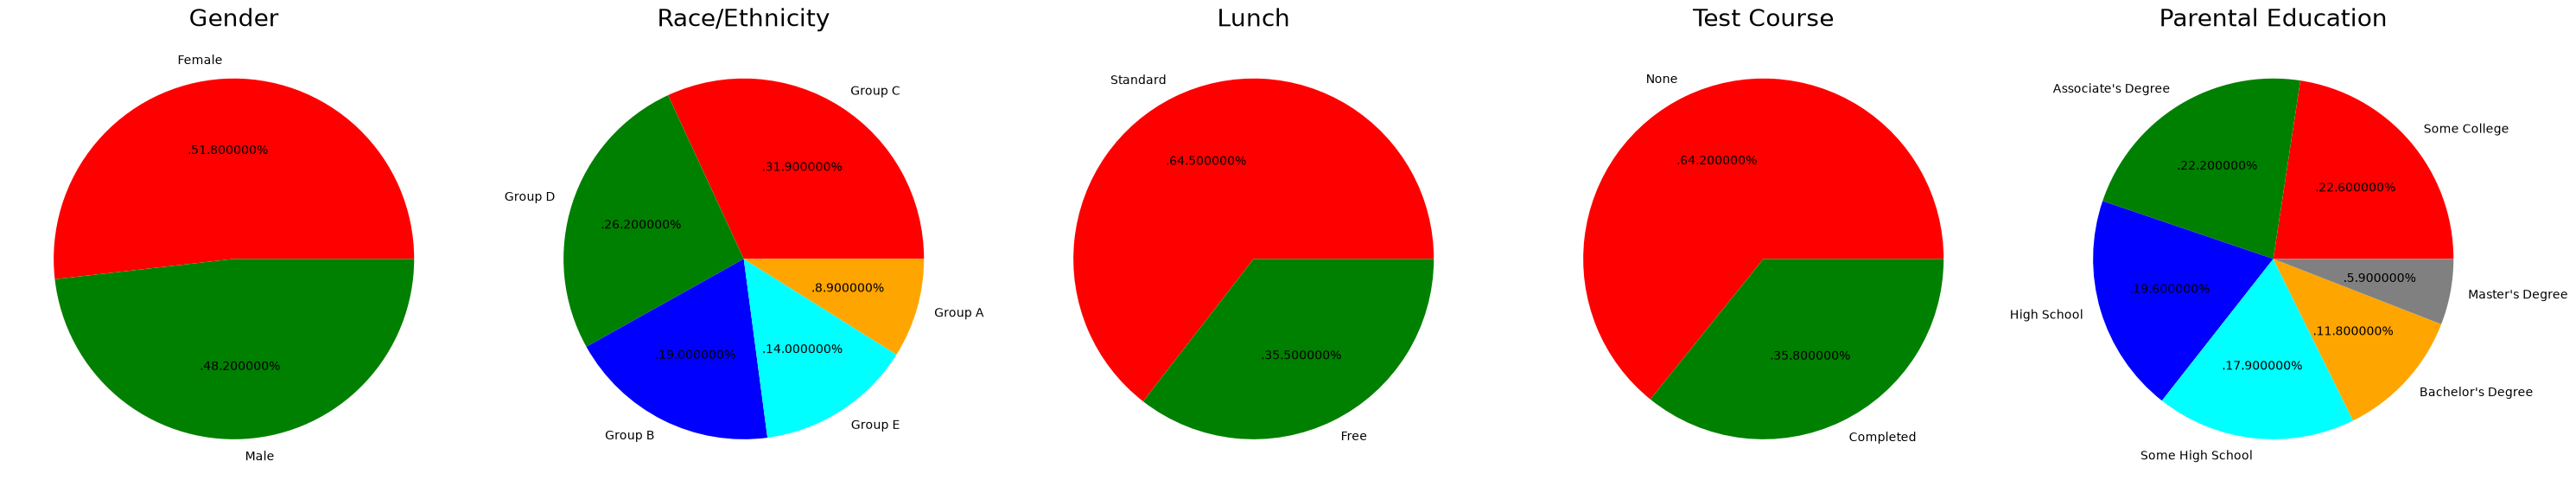

In [64]:
plt.rcParams["figure.figsize"] = (30, 12)

plt.subplot(1, 5, 1)
size = df["gender"].value_counts()
labels = "Female", "Male"
color = ["red", "green"]

plt.pie(size, colors=color, labels=labels, autopct=".%2f%%")
plt.title("Gender", fontsize=20)
plt.axis("off")

plt.subplot(1, 5, 2)
size = df["race_ethnicity"].value_counts()
labels = "Group C", "Group D", "Group B", "Group E", "Group A"
color = ["red", "green", "blue", "cyan", "orange"]

plt.pie(size, colors=color, labels=labels, autopct=".%2f%%")
plt.title("Race/Ethnicity", fontsize=20)
plt.axis("off")

plt.subplot(1, 5, 3)
size = df["lunch"].value_counts()
labels = "Standard", "Free"
color = ["red", "green"]

plt.pie(size, colors=color, labels=labels, autopct=".%2f%%")
plt.title("Lunch", fontsize=20)
plt.axis("off")


plt.subplot(1, 5, 4)
size = df["test_preparation_course"].value_counts()
labels = "None", "Completed"
color = ["red", "green"]

plt.pie(size, colors=color, labels=labels, autopct=".%2f%%")
plt.title("Test Course", fontsize=20)
plt.axis("off")

plt.subplot(1, 5, 5)
size = df["parental_level_of_education"].value_counts()
labels = "Some College", "Associate's Degree", "High School", "Some High School", "Bachelor's Degree", "Master's Degree"
color = ["red", "green", "blue", "cyan", "orange", "grey"]

plt.pie(size, colors=color, labels=labels, autopct=".%2f%%")
plt.title("Parental Education", fontsize=20)
plt.axis("off")


plt.tight_layout()
plt.grid()

plt.show()

**Insights:**  
- Number of Male and Female students is almost equal
- Number students are greatest in Group C
- Number of students who have standard lunch are greater
- Number of students who have not enrolled in any test preparation course is greater
- Number of students whose parental education is "Some College" is greater followed closely by "Associate's Degree"

**4.4 Feature-wise Visualization**

4.4.1 Gender Column  
- How is distribution of Gender?
- Is gender has any impact on student's performance?

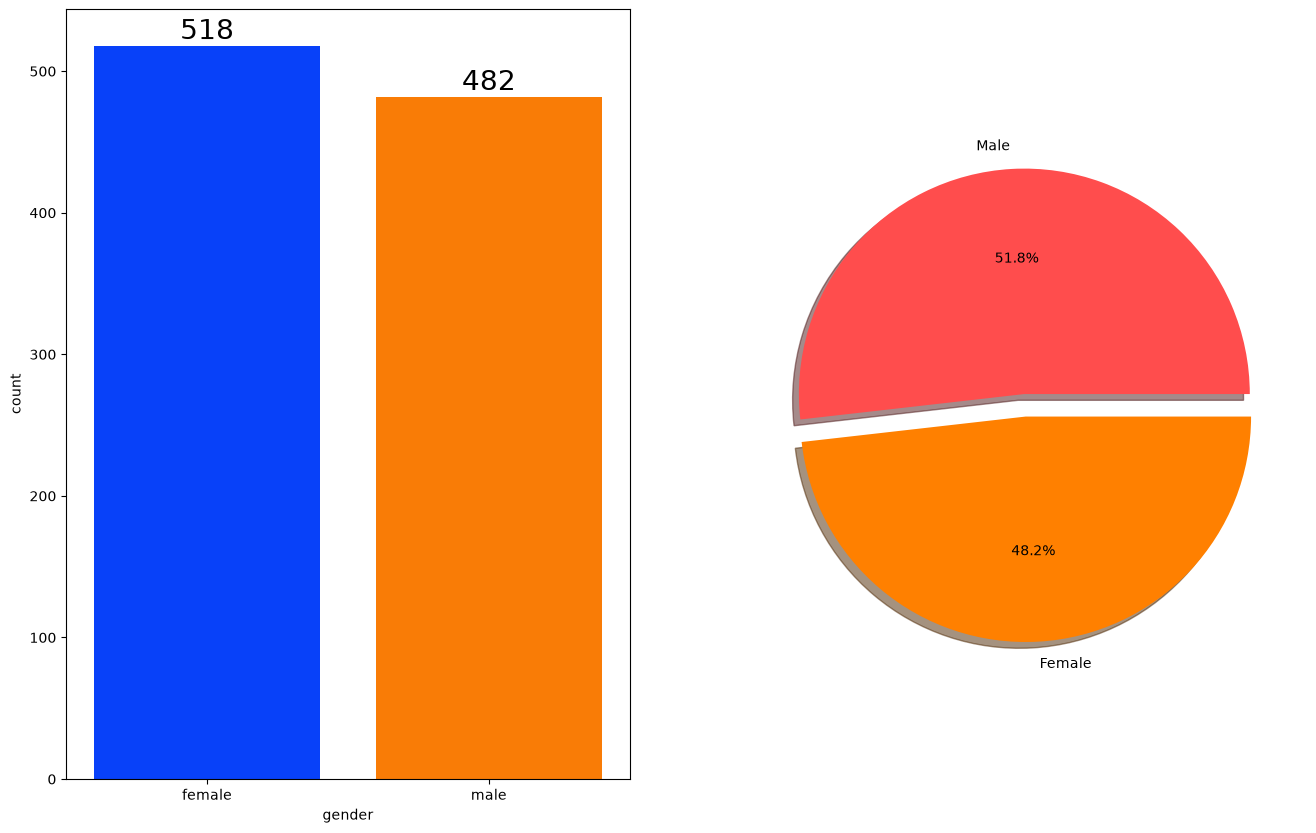

In [69]:
f, ax = plt.subplots(1, 2, figsize=(16,10))

sns.countplot(data=df, x=df["gender"], palette="bright", ax=ax[0], saturation=0.95)

for container in ax[0].containers:
    ax[0].bar_label(container, color="black", size=20)
    
plt.pie(x=df["gender"].value_counts(), labels=["Male", "Female"], explode=[0,0.1], autopct="%1.1f%%", shadow=True, colors=["#ff4d4d","#ff8000"])

plt.show()

**Insight:**  
- Gender has balanced data with female students being 518 (48%) and male students being 482 (52%).

In [72]:
gender_group = df.groupby("gender")[["math_score", "reading_score", "writing_score", "average_score"]].mean()
gender_group

,math_score,reading_score,writing_score,average_score
gender,,,,
female,63.633205,72.608108,72.467181,69.569498
male,68.728216,65.473029,63.311203,65.837483


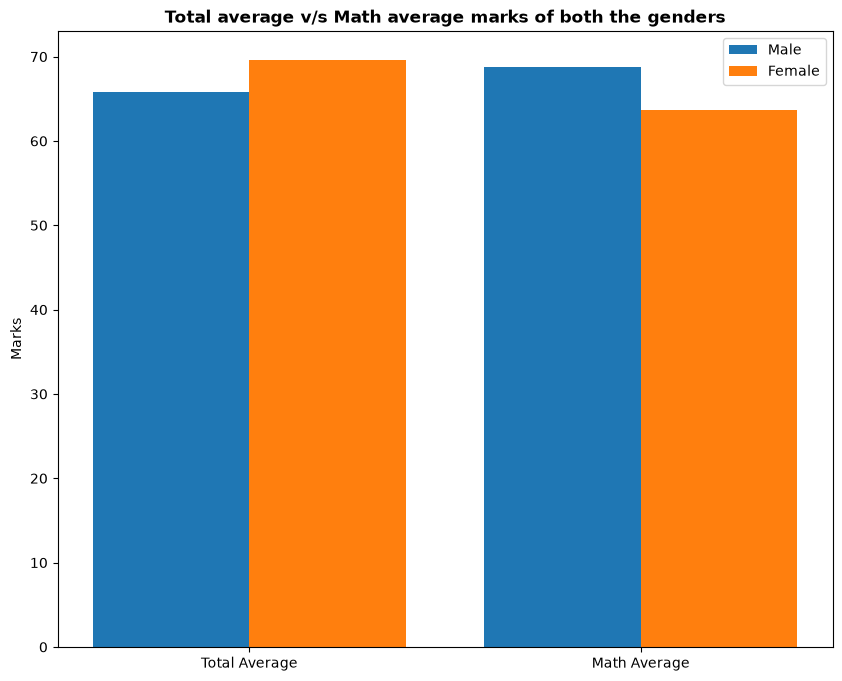

In [80]:
plt.figure(figsize=(10, 8))

X = ["Total Average", "Math Average"]

female_scores = [gender_group["average_score"].iloc[0], gender_group["math_score"].iloc[0]]
male_scores = [gender_group["average_score"].iloc[1], gender_group["math_score"].iloc[1]]

X_axis = np.arange(len(X))

plt.bar(X_axis - 0.2, male_scores, 0.4, label = "Male")
plt.bar(X_axis + 0.2, female_scores, 0.4, label = "Female")
  
plt.xticks(X_axis, X)
plt.ylabel("Marks")
plt.title("Total average v/s Math average marks of both the genders", fontweight="bold")

plt.legend()
plt.show()

**Insights:** 
- On an average females have a better overall score than men, whereas males have scored higher in Maths.

4.4.2 Race / Ethnicity Column
- How is Group wise distribution?
- Does Race/Ethnicity has any impact on student's performance?

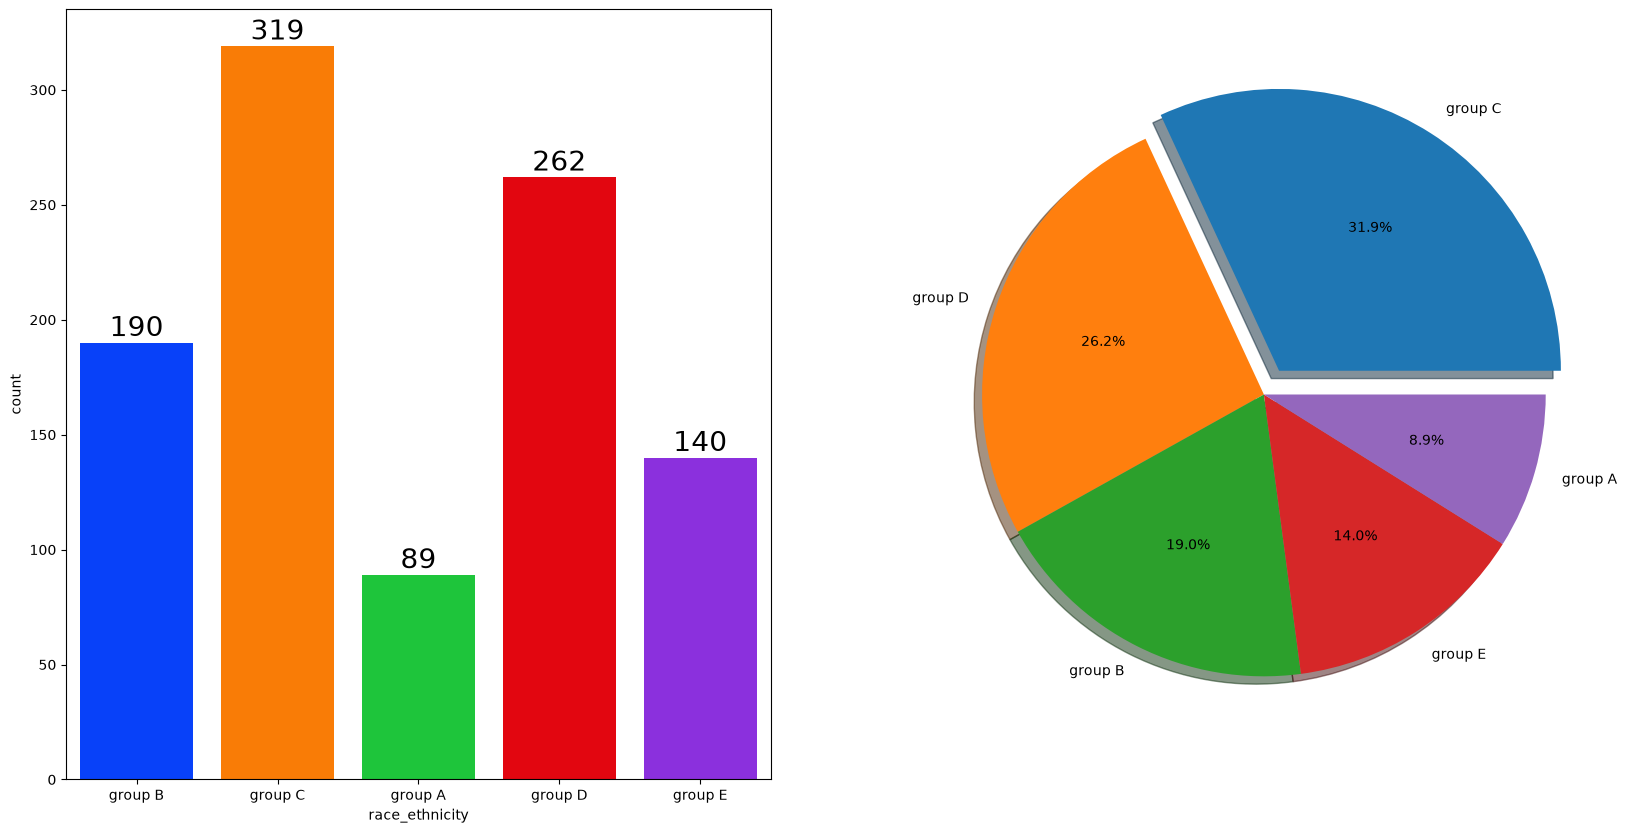

In [81]:
f, ax = plt.subplots(1, 2, figsize=(20,10))

sns.countplot(data=df, x=df["race_ethnicity"], palette="bright", ax=ax[0], saturation=0.95)

for container in ax[0].containers:
    ax[0].bar_label(container, color="black", size=20)

plt.pie(x=df["race_ethnicity"].value_counts(), labels=df["race_ethnicity"].value_counts().index, explode=[0.1,0,0,0,0], autopct="%1.1f%%", shadow=True)

plt.show()

**Insights:**  
- Most of the student are belonging from Group C / Group D.
- Group A has lowest number of students.

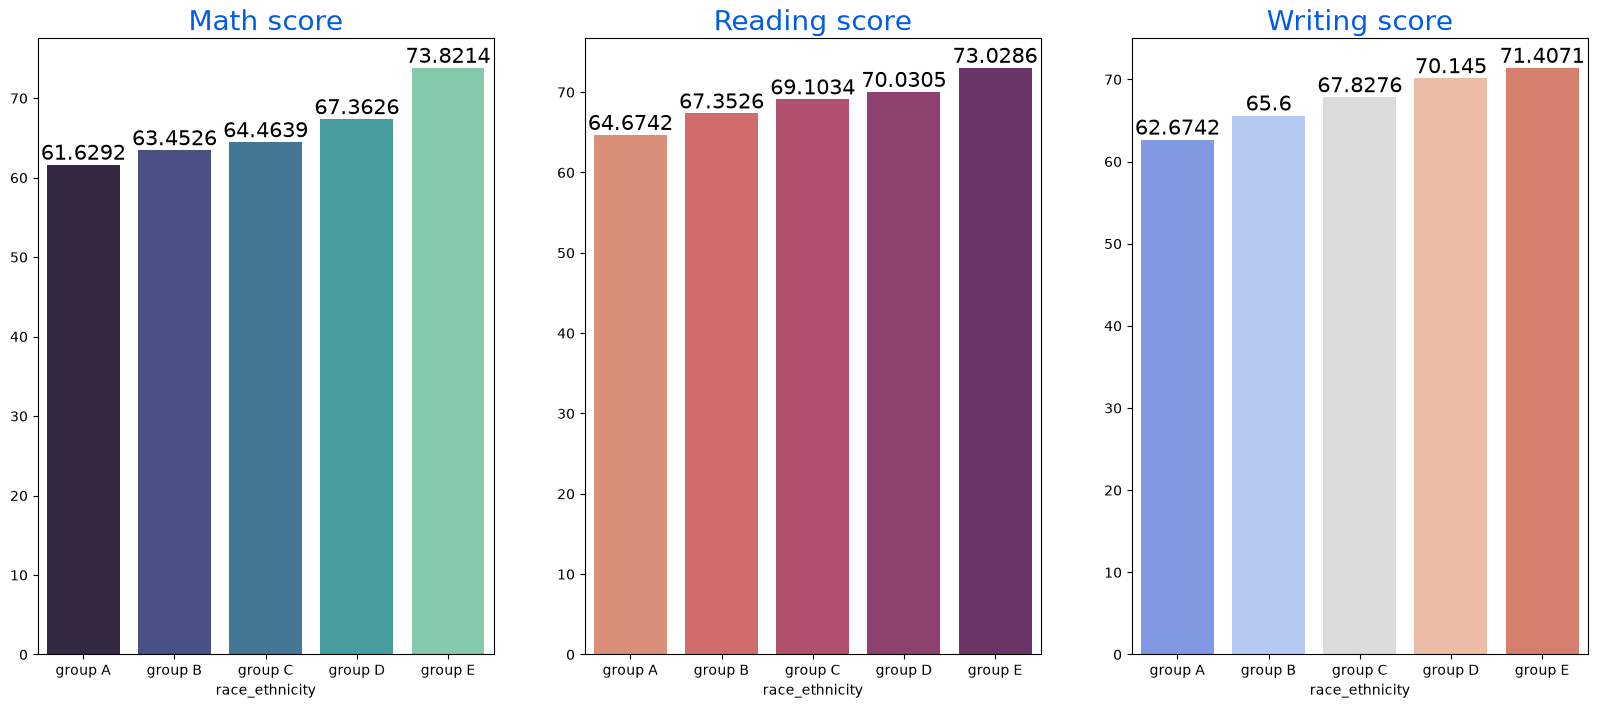

In [82]:
Group_data2 = df.groupby("race_ethnicity")
f, ax = plt.subplots(1, 3, figsize=(20,8))

sns.barplot(x=Group_data2["math_score"].mean().index, y=Group_data2["math_score"].mean().values, palette="mako", ax=ax[0])
ax[0].set_title("Math score",color="#005ce6", size=20)

for container in ax[0].containers:
    ax[0].bar_label(container, color="black", size=15)

sns.barplot(x=Group_data2["reading_score"].mean().index, y=Group_data2["reading_score"].mean().values, palette="flare", ax=ax[1])
ax[1].set_title("Reading score", color="#005ce6", size=20)

for container in ax[1].containers:
    ax[1].bar_label(container, color="black", size=15)

sns.barplot(x=Group_data2["writing_score"].mean().index, y=Group_data2["writing_score"].mean().values, palette="coolwarm", ax=ax[2])
ax[2].set_title("Writing score", color="#005ce6", size=20)

for container in ax[2].containers:
    ax[2].bar_label(container, color="black", size=15)

plt.show()

**Insights:** 
- Group E students have scored the highest marks.
- Group A students have scored the lowest marks.
- Students from a lower Socioeconomic status have a lower avg in all course subjects.

4.4.3 Parental Level of Education Column  
- What is educational background of student's parent?
- Is parental education has any impact on student's performance?

findfont: Failed to find font weight 30 for DejaVu Sans, now using 400.


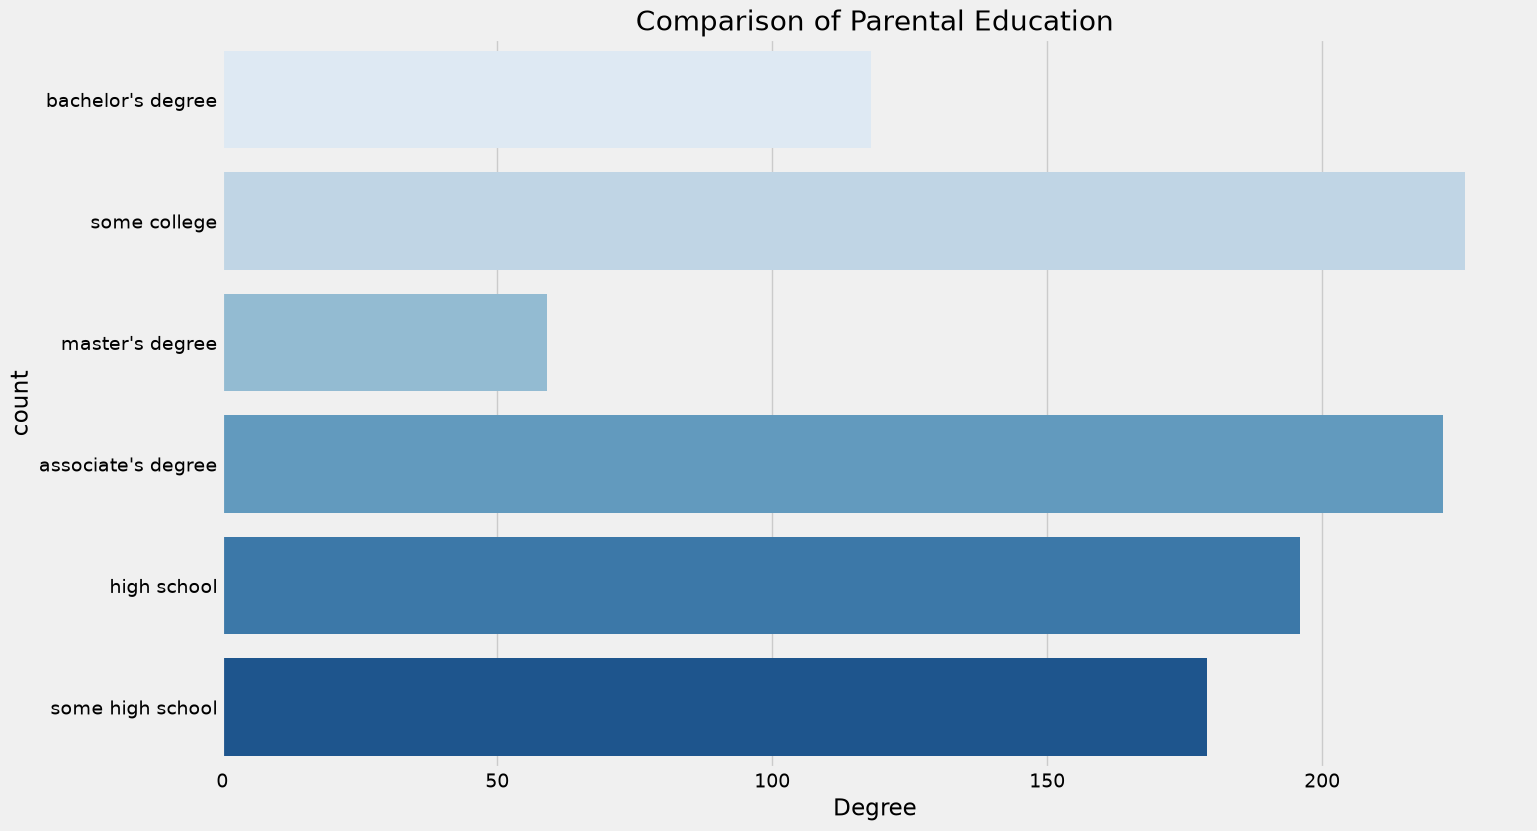

In [83]:
plt.rcParams["figure.figsize"] = (15, 9)
plt.style.use("fivethirtyeight")

sns.countplot(df["parental_level_of_education"], palette="Blues")

plt.title("Comparison of Parental Education", fontweight=30, fontsize=20)
plt.xlabel("Degree")
plt.ylabel("count")

plt.show()

**Insight:**  
- Largest number of parents have some college education.

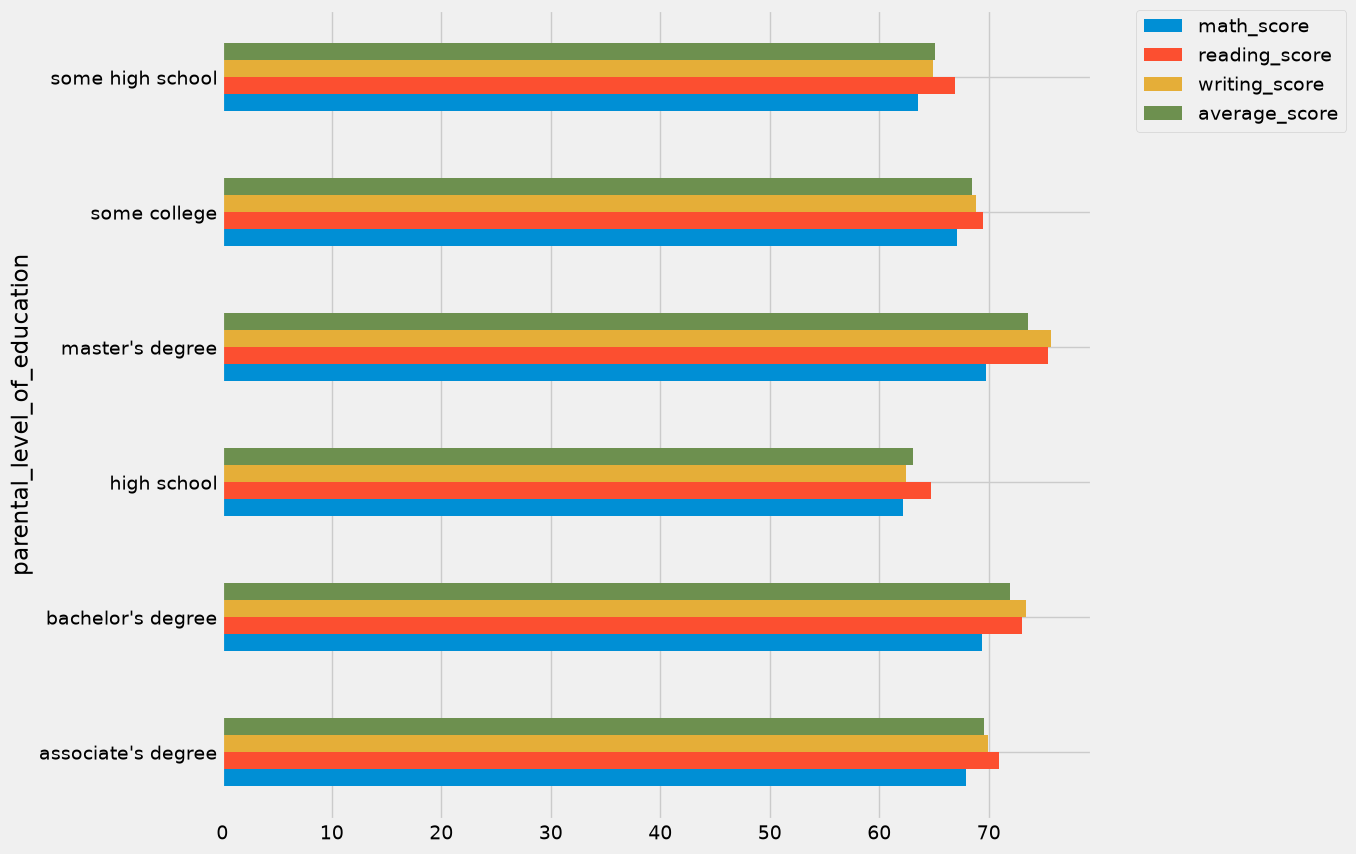

In [90]:
df.groupby("parental_level_of_education")[["math_score", "reading_score", "writing_score", "average_score"]].mean().plot(kind="barh", figsize=(10,10))

plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.show()

**Insight:**  
- The score of student whose parents possess master and bachelor level education are higher than others.

4.4.4 Lunch column  
- Which type of lunch is most common amoung students?
- What is the effect of lunch type on test results?

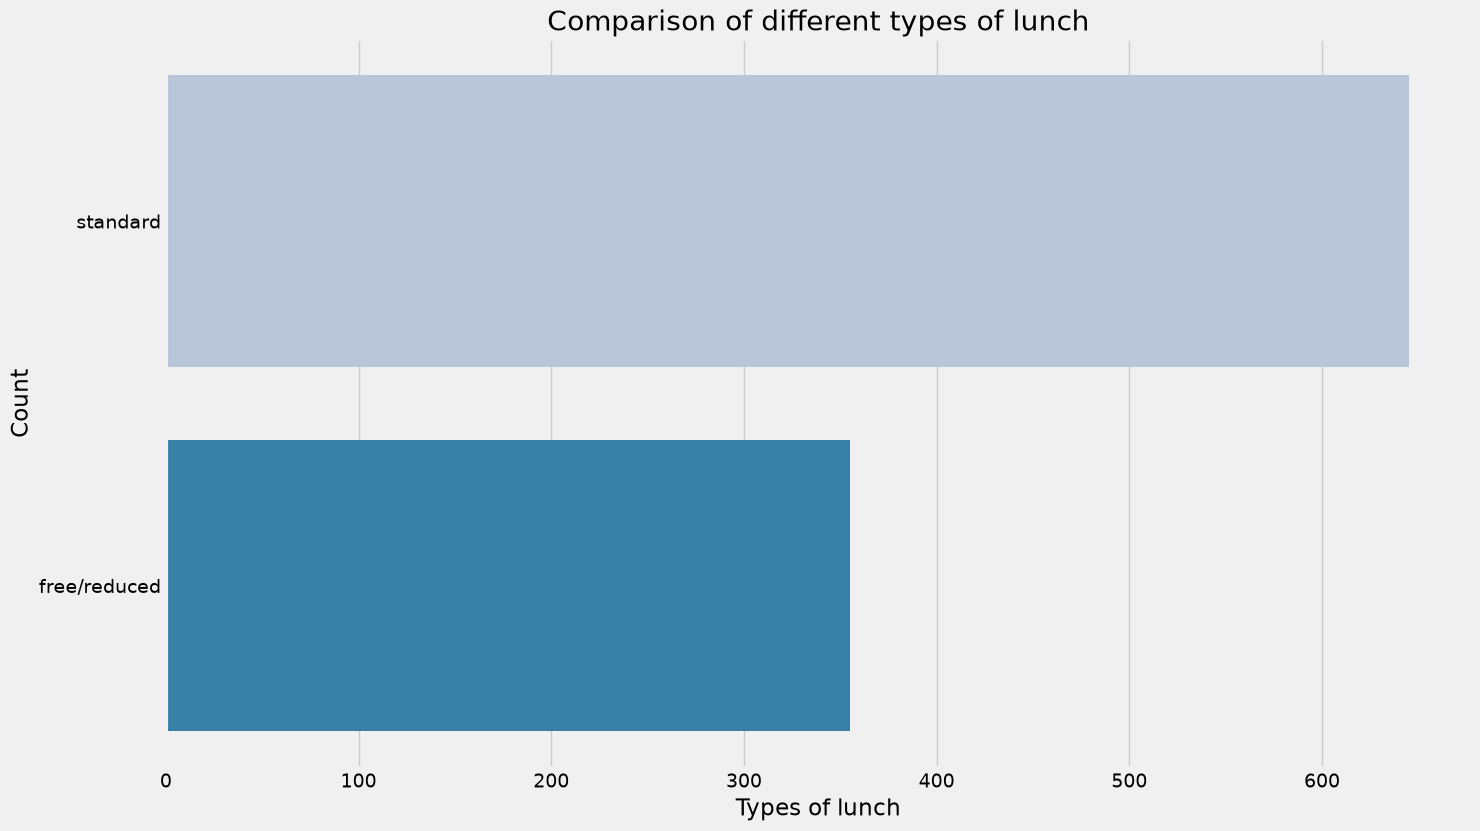

In [92]:
plt.rcParams["figure.figsize"]=(15, 9)

sns.countplot(df["lunch"], palette="PuBu")

plt.title("Comparison of different types of lunch", fontweight=30, fontsize=20)
plt.xlabel("Types of lunch")
plt.ylabel("Count")

plt.show()

**Insight:**  
- Students being served Standard lunch was more than free lunch.

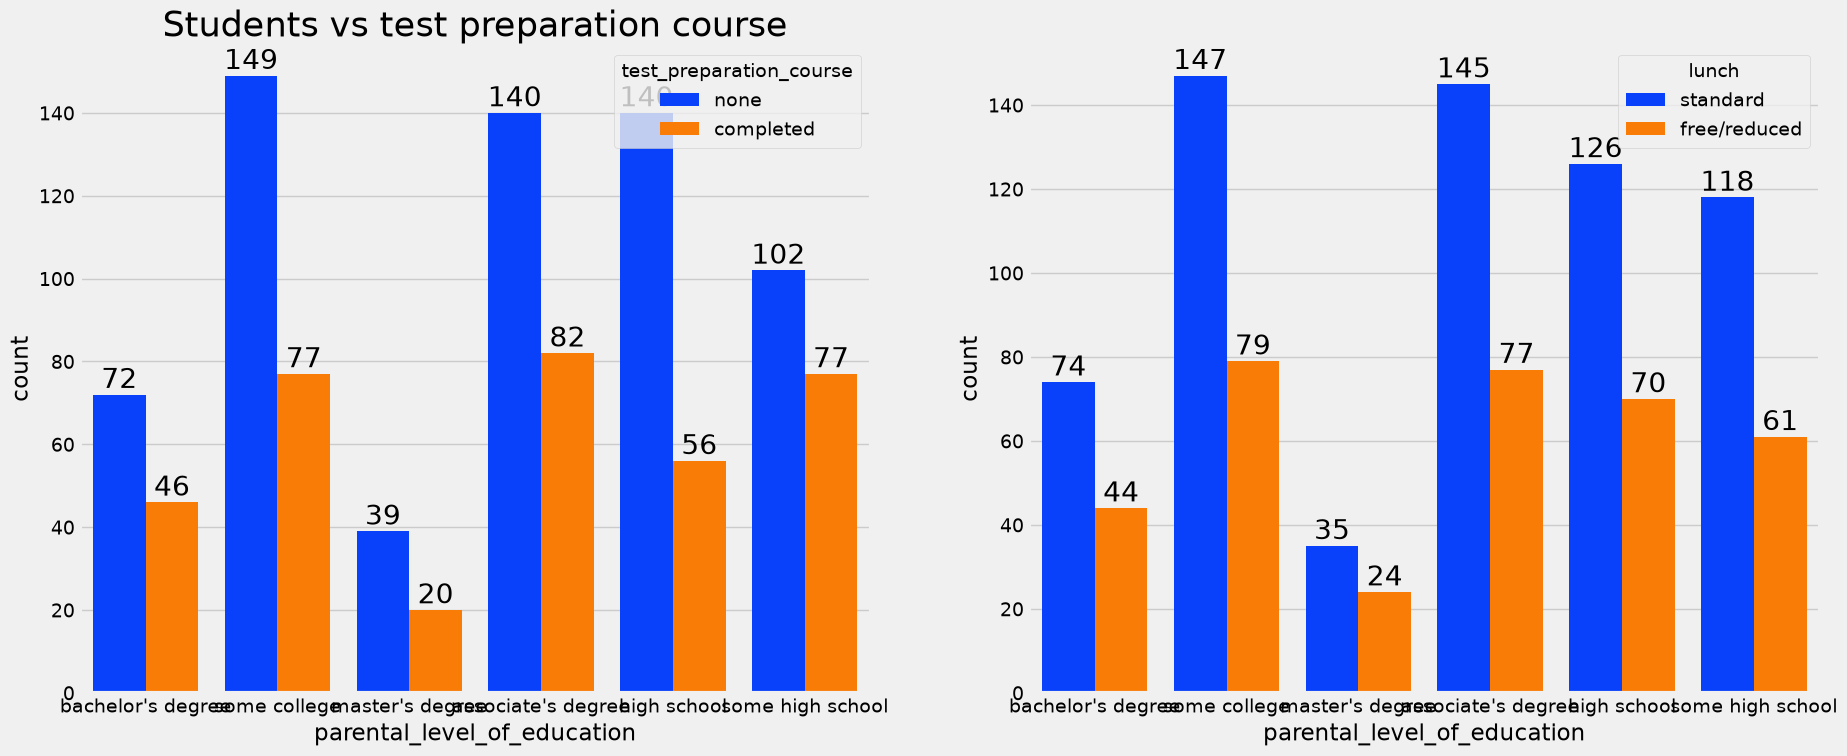

In [94]:
f, ax = plt.subplots(1, 2, figsize=(20,8))

sns.countplot(data=df, x=df["parental_level_of_education"], palette="bright", hue="test_preparation_course", saturation=0.95, ax=ax[0])
ax[0].set_title("Students vs test preparation course", color="black", size=25)

for container in ax[0].containers:
    ax[0].bar_label(container, color="black", size=20)
    
sns.countplot(data=df, x=df["parental_level_of_education"], palette="bright", hue="lunch", saturation=0.95, ax=ax[1])

for container in ax[1].containers:
    ax[1].bar_label(container, color="black", size=20)   

plt.show()

**Insight:**  
- Students who get Standard Lunch tend to perform better than students who got free/reduced lunch.

4.4.5 Test Preparation Course Column  
- Which type of lunch is most common amoung students?
- Is Test prepration course has any impact on student's performance?

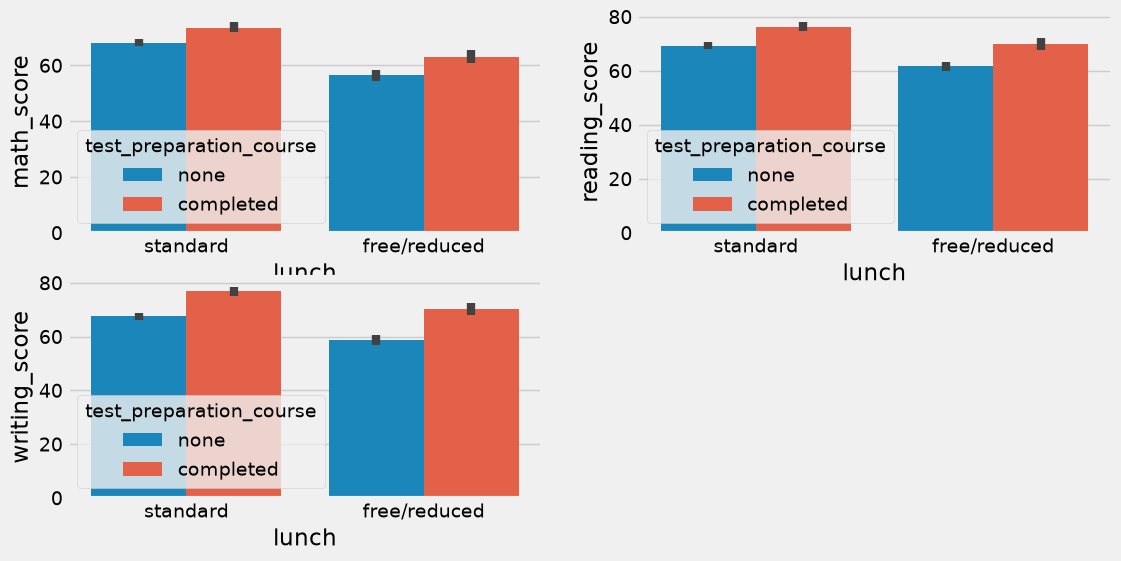

In [95]:
plt.figure(figsize=(12,6))

plt.subplot(2,2,1)
sns.barplot (x=df["lunch"], y=df["math_score"], hue=df["test_preparation_course"])

plt.subplot(2,2,2)
sns.barplot (x=df["lunch"], y=df["reading_score"], hue=df["test_preparation_course"])

plt.subplot(2,2,3)
sns.barplot (x=df["lunch"], y=df["writing_score"], hue=df["test_preparation_course"])

plt.show()

**Insight:** 
- Students who have completed the Test Prepration Course have scores higher in all three categories than those who haven't taken the course.

4.4.6 Checking Outliers

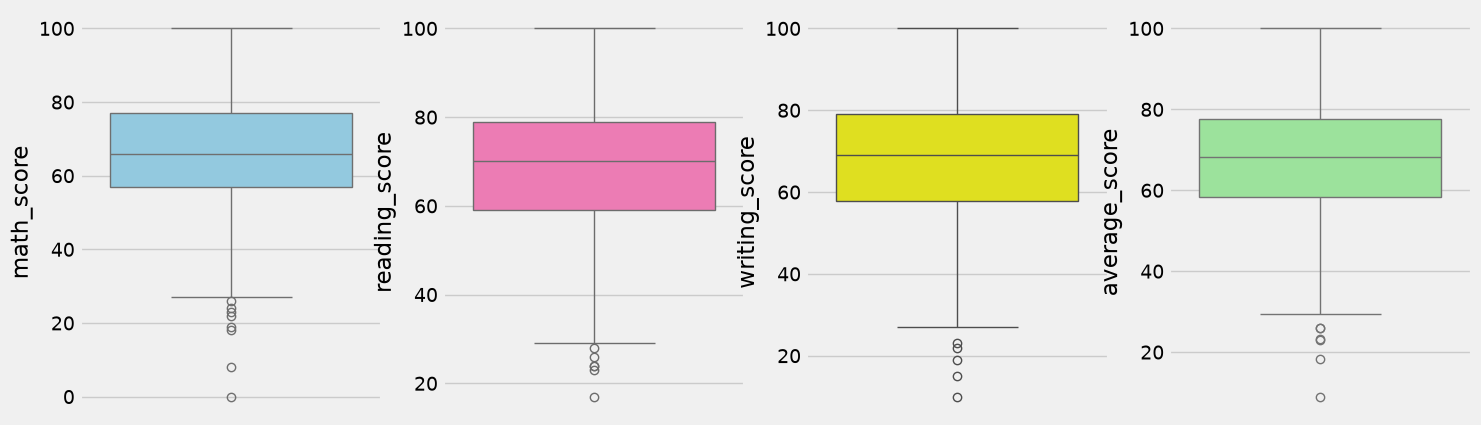

In [96]:
plt.subplots(1,4,figsize=(16,5))

plt.subplot(141)
sns.boxplot(df["math_score"], color="skyblue")

plt.subplot(142)
sns.boxplot(df["reading_score"], color="hotpink")

plt.subplot(143)
sns.boxplot(df["writing_score"], color="yellow")

plt.subplot(144)
sns.boxplot(df["average_score"], color="lightgreen")

plt.show()

4.4.7 Multivariate Analysis using Pairplot

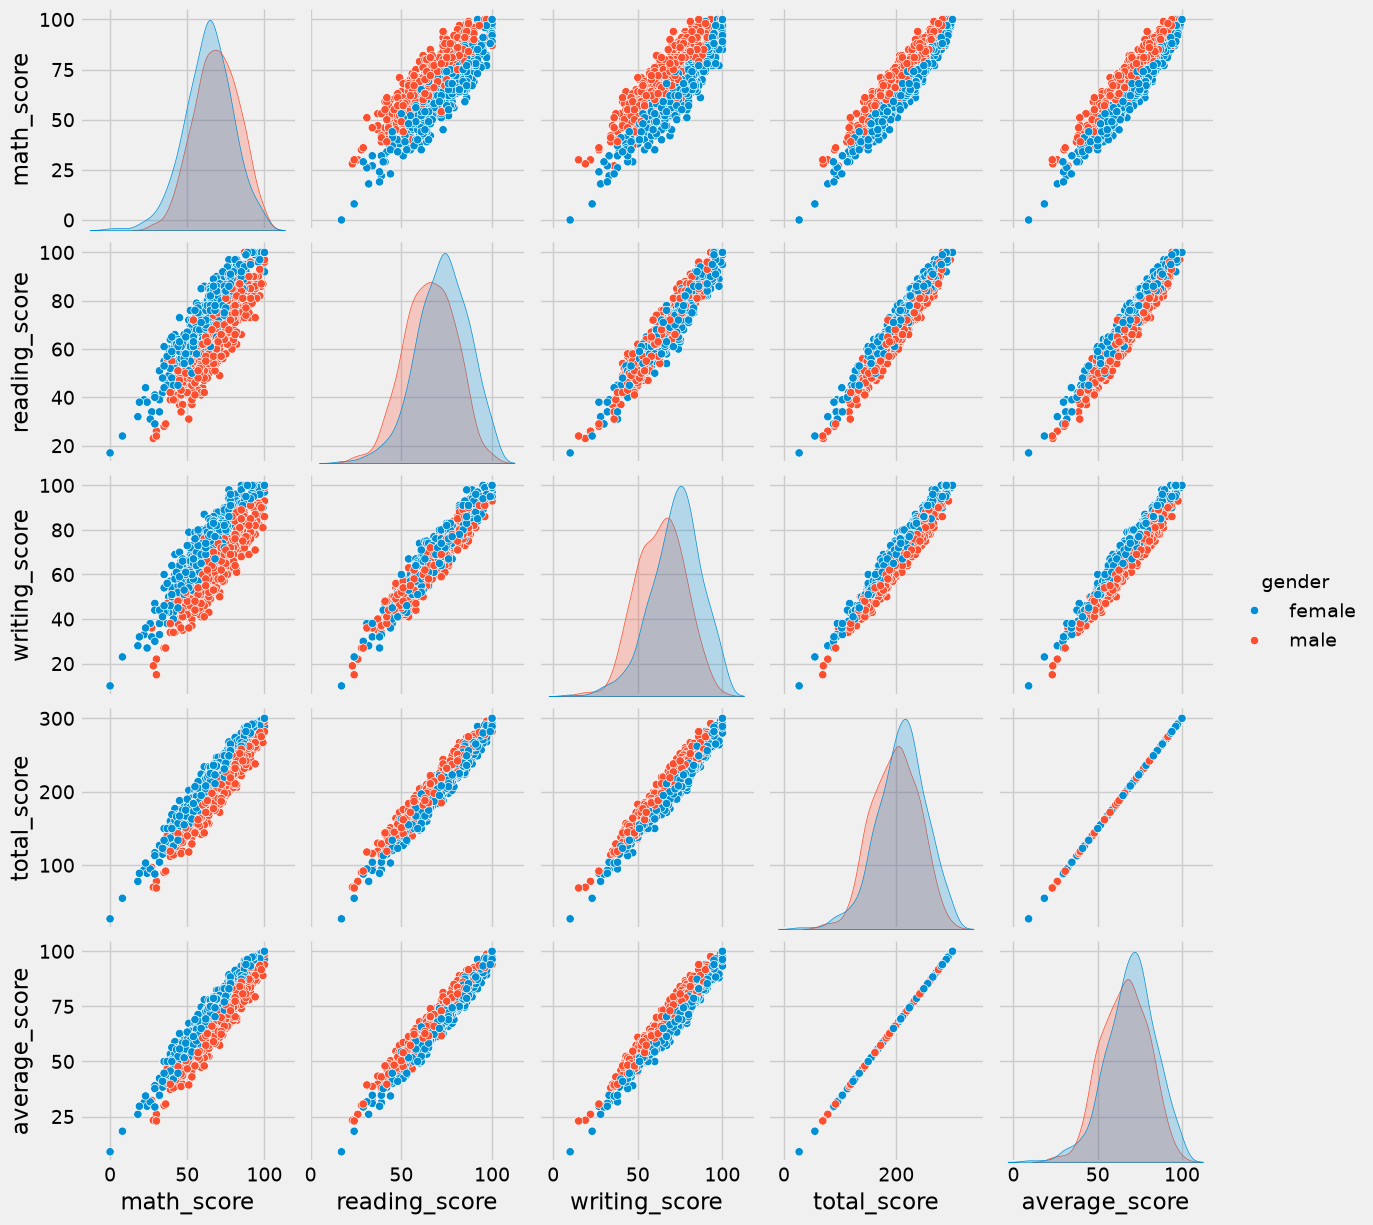

In [97]:
sns.pairplot(df, hue="gender")
plt.show()

**Insight:**  
- From the above plot it is clear that all the scores increase linearly with each other.

#### 5) Conclusions
- Student's Performance is related with lunch, race, parental level education.
- Females lead in pass percentage and also are top-scorers.
- Student's Performance is not much related with test preparation course.
- Finishing preparation course is benefitial.